In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
data = pd.read_csv("datasets/clustering/Country-data.csv")

In [4]:
data.head()

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   country     167 non-null    object 
 1   child_mort  167 non-null    float64
 2   exports     167 non-null    float64
 3   health      167 non-null    float64
 4   imports     167 non-null    float64
 5   income      167 non-null    int64  
 6   inflation   167 non-null    float64
 7   life_expec  167 non-null    float64
 8   total_fer   167 non-null    float64
 9   gdpp        167 non-null    int64  
dtypes: float64(7), int64(2), object(1)
memory usage: 13.2+ KB


In [6]:
data.describe().T


,count,mean,std,min,25%,50%,75%,max
child_mort,167.0,38.270060,40.328931,2.6000,8.250,19.30,62.10,208.00
exports,167.0,41.108976,27.412010,0.1090,23.800,35.00,51.35,200.00
health,167.0,6.815689,2.746837,1.8100,4.920,6.32,8.60,17.90
imports,167.0,46.890215,24.209589,0.0659,30.200,43.30,58.75,174.00
income,167.0,17144.688623,19278.067698,609.0000,3355.000,9960.00,22800.00,125000.00
inflation,167.0,7.781832,10.570704,-4.2100,1.810,5.39,10.75,104.00
life_expec,167.0,70.555689,8.893172,32.1000,65.300,73.10,76.80,82.80
total_fer,167.0,2.947964,1.513848,1.1500,1.795,2.41,3.88,7.49
gdpp,167.0,12964.155689,18328.704809,231.0000,1330.000,4660.00,14050.00,105000.00


In [7]:
data.columns

Index(['country', 'child_mort', 'exports', 'health', 'imports', 'income',
       'inflation', 'life_expec', 'total_fer', 'gdpp'],
      dtype='object')

In [8]:
data.shape

(167, 10)

In [9]:
missing_values = data.isnull().sum()
missing_columns = missing_values[missing_values > 0]
missing_columns

Series([], dtype: int64)

In [10]:
num = data.drop('country' , axis =1)
num

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200
...,...,...,...,...,...,...,...,...,...
162,29.2,46.6,5.25,52.7,2950,2.62,63.0,3.50,2970
163,17.1,28.5,4.91,17.6,16500,45.90,75.4,2.47,13500
164,23.3,72.0,6.84,80.2,4490,12.10,73.1,1.95,1310
165,56.3,30.0,5.18,34.4,4480,23.60,67.5,4.67,1310


In [11]:
correlation_matrix = num.corr()
correlation_matrix

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
child_mort,1.000000,-0.318093,-0.200402,-0.127211,-0.524315,0.288276,-0.886676,0.848478,-0.483032
exports,-0.318093,1.000000,-0.114408,0.737381,0.516784,-0.107294,0.316313,-0.320011,0.418725
health,-0.200402,-0.114408,1.000000,0.095717,0.129579,-0.255376,0.210692,-0.196674,0.345966
imports,-0.127211,0.737381,0.095717,1.000000,0.122406,-0.246994,0.054391,-0.159048,0.115498
income,-0.524315,0.516784,0.129579,0.122406,1.000000,-0.147756,0.611962,-0.501840,0.895571
inflation,0.288276,-0.107294,-0.255376,-0.246994,-0.147756,1.000000,-0.239705,0.316921,-0.221631
life_expec,-0.886676,0.316313,0.210692,0.054391,0.611962,-0.239705,1.000000,-0.760875,0.600089
total_fer,0.848478,-0.320011,-0.196674,-0.159048,-0.501840,0.316921,-0.760875,1.000000,-0.454910
gdpp,-0.483032,0.418725,0.345966,0.115498,0.895571,-0.221631,0.600089,-0.454910,1.000000


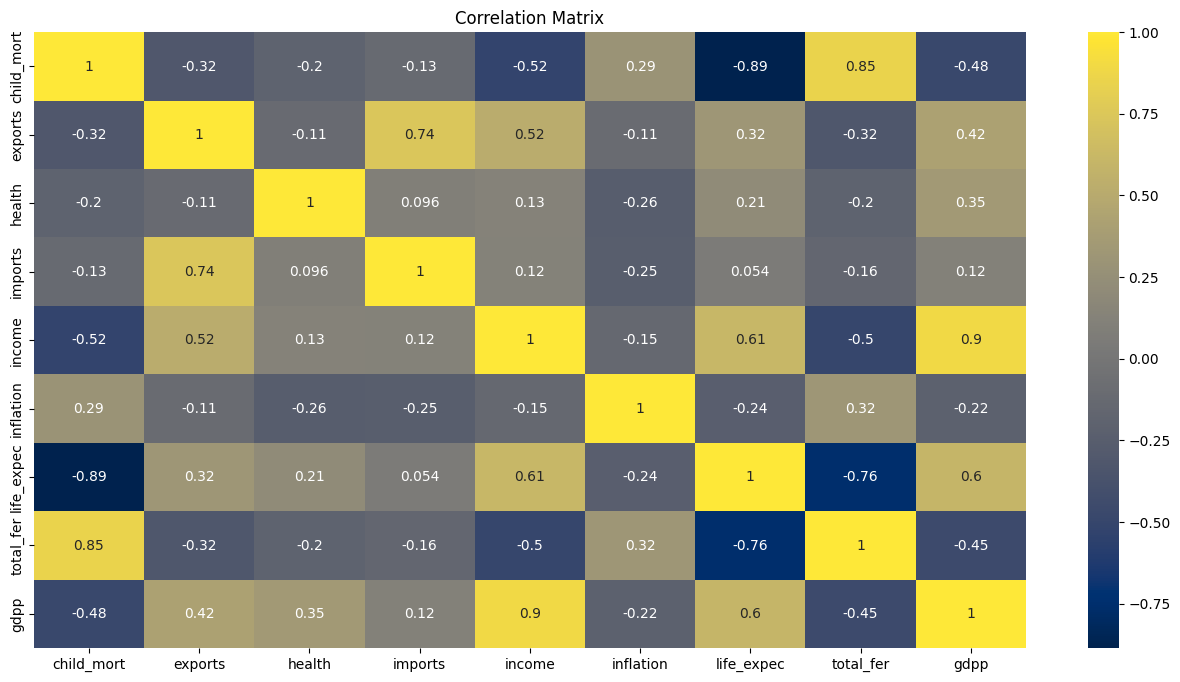

In [12]:
plt.figure(figsize=(16, 8))
sns.heatmap(correlation_matrix, annot=True,cmap='cividis')
plt.title('Correlation Matrix')
plt.show()

Korelasyon Analizi

#### Güçlü Pozitif Korelasyonlar

Income ve gdpp: 0.9 olan güçlü pozitif korelasyon, daha yüksek gelir düzeyine sahip ülkelerin genellikle daha yüksek kişi başına GSYİH’ya sahip olduğunu göstermektedir.

Exports ve Imports: 0.74 olan korelasyon, artan ihracatın genellikle ülkelerde daha yüksek ithalat seviyeleri ile ilişkili olduğunu öne sürmektedir.

child_mort ve total_fer: 0.85’lik güçlü pozitif korelasyon, daha yüksek çocuk ölüm oranına sahip ülkelerin genellikle daha yüksek doğurganlık oranlarına sahip olduğunu belirtmektedir.

#### Orta Pozitif Korelasyonlar:

life_expec ve total_fer
0.61'lik orta düzeyde bir korelasyon, daha yüksek hayat beklentisine sahip ülkelerin genellikle daha yüksek gelir seviyelerine sahip olduğunu gösterir.

#### Orta Düzeyde Negatif Korelasyonlar:

gdpp ve total_fer
-0.45 olan bu korelasyon, kişi başına düşen GSYİH'nın artmasının genellikle daha düşük doğurganlık oranlarıyla ilişkilendirildiğini göstermektedir.

#### Güçlü Negatif Korelasyonlar:

total_fer ve life_expec arasında -0.76'lık bir korelasyon vardır. Bu, yüksek doğurganlık oranına sahip ülkelerin genellikle daha düşük yaşam beklentisi yaşadığını göstermektedir.

Zayıf Korelasyonlar:

health child_mort

-0.2 değerinde çok zayıf bir korelasyon, sağlık göstergeleri ile çocuk ölüm oranları arasında çok az veya hiç ilişki olmadığını gösterir.

#### Yüksek Pozitif Korelasyon

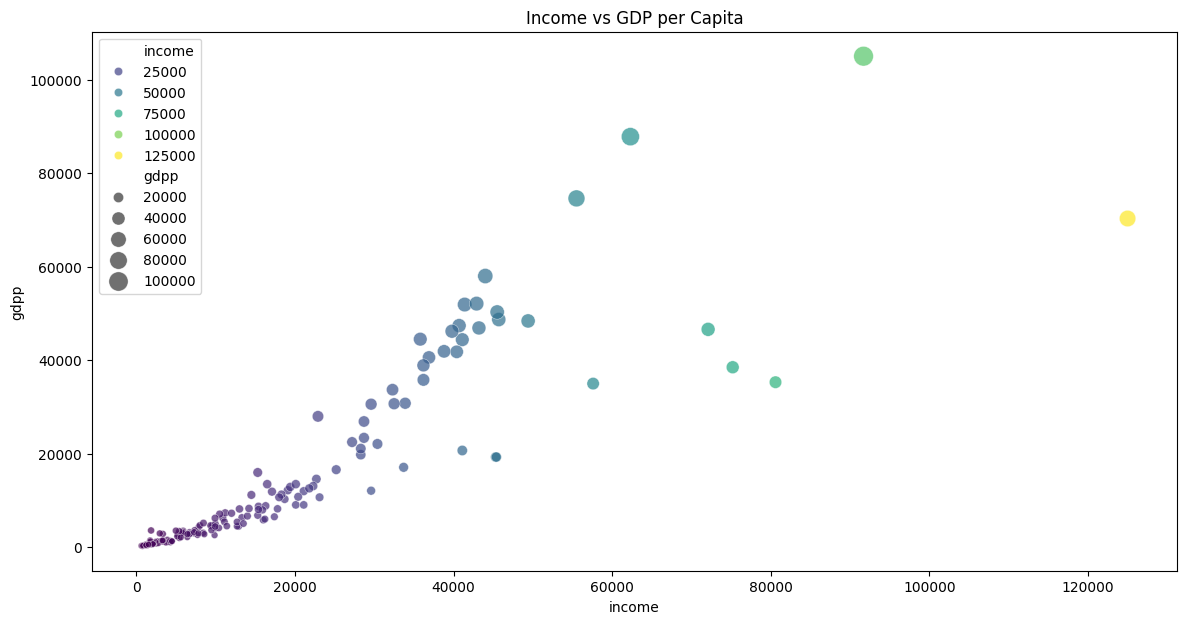

In [13]:
plt.figure(figsize=(14, 7))
sns.scatterplot(data=data, x='income', y='gdpp', hue='income', palette='viridis', alpha=0.7 , size='gdpp', sizes=(20, 200))
plt.title('Income vs GDP per Capita')
plt.show()

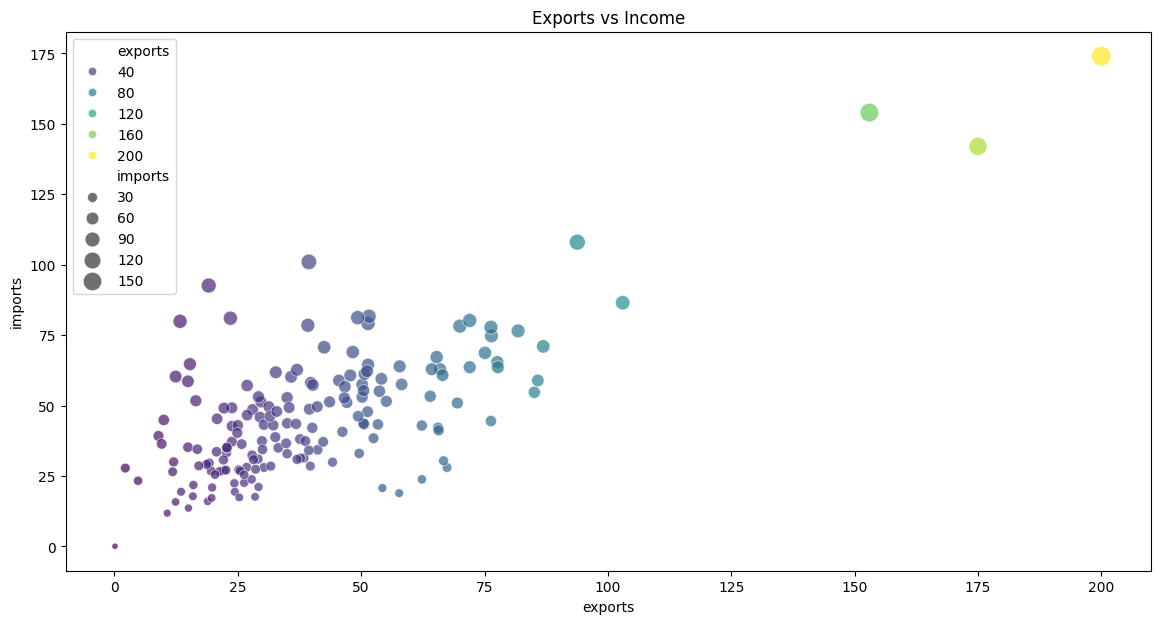

In [14]:
plt.figure(figsize=(14,7))
sns.scatterplot(data=data, x='exports', y='imports' , hue='exports', palette='viridis' , alpha=0.7 , size='imports' , sizes=(20,200))
plt.title('Exports vs Income')
plt.show()

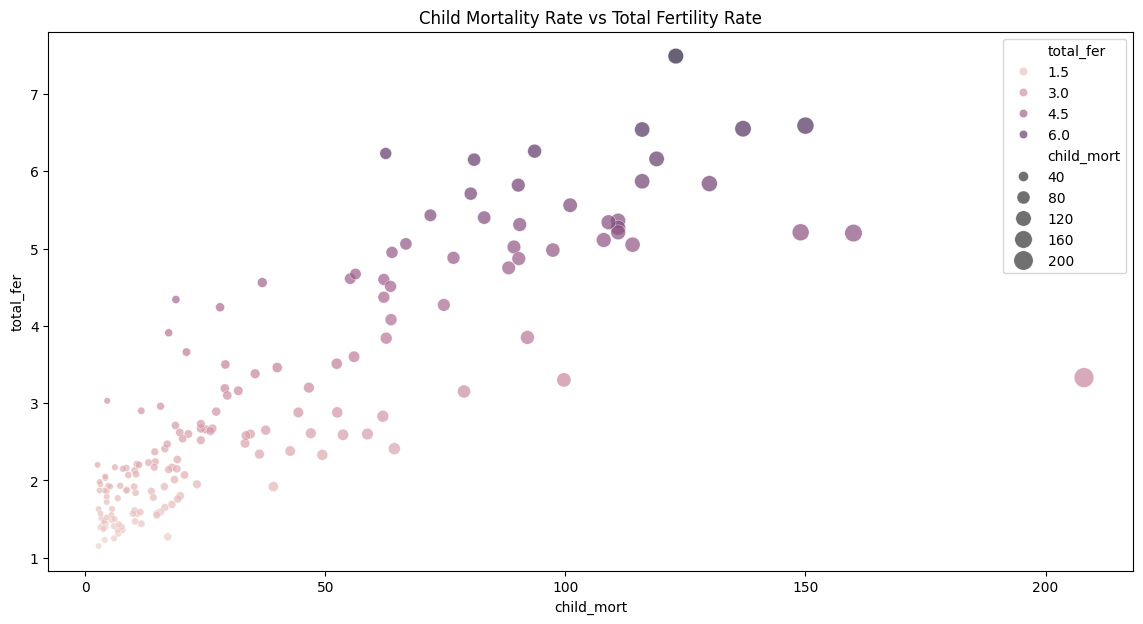

In [15]:
plt.figure(figsize=(14,7))
sns.scatterplot(data=data, x='child_mort', y='total_fer' , hue='total_fer' , alpha=0.7 , size='child_mort' , sizes=(20,200))
plt.title('Child Mortality Rate vs Total Fertility Rate')
plt.show()

#### Orta Düzey Pozitif Korelasyon

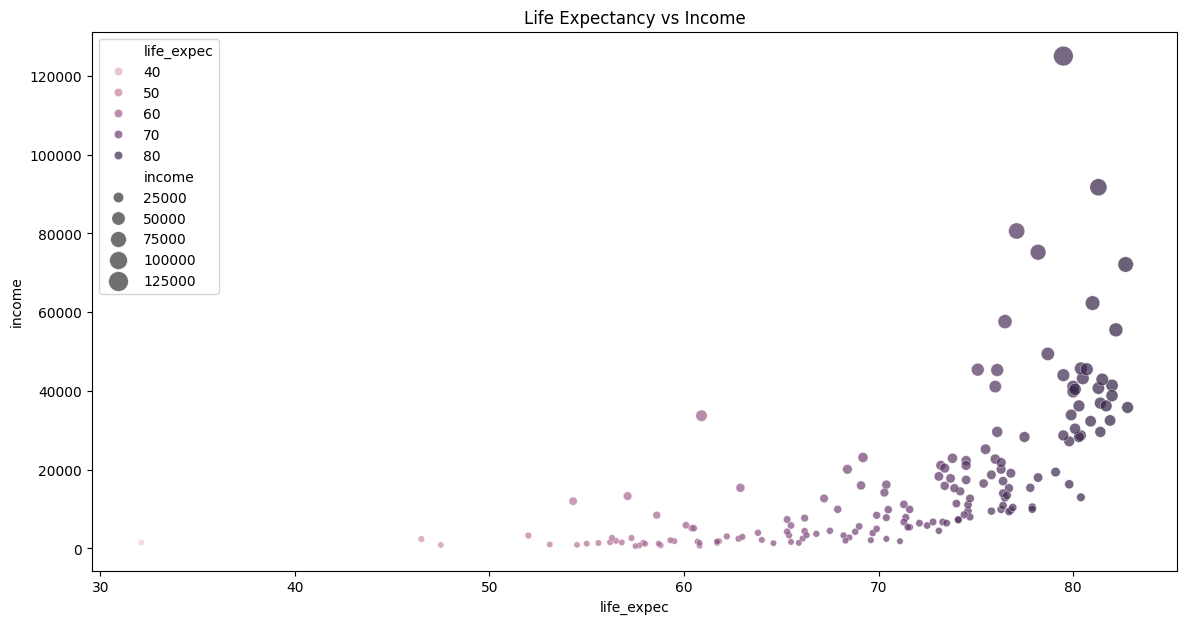

In [16]:
plt.figure(figsize=(14,7))
sns.scatterplot(data=data, x='life_expec', y='income', hue='life_expec' , alpha=0.7 , size='income' , sizes=(20,200))
plt.title('Life Expectancy vs Income')
plt.show()

#### Orta Düzey Negatif Korelasyon

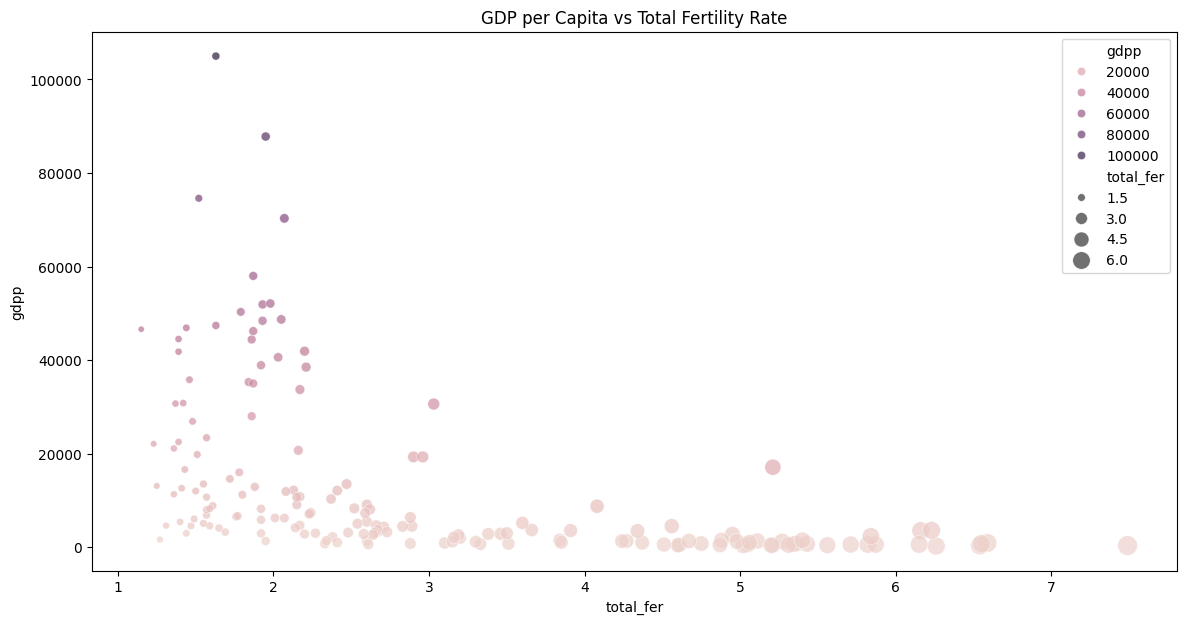

In [17]:
plt.figure(figsize=(14,7))
sns.scatterplot(data=data, x='total_fer', y='gdpp', hue='gdpp' , alpha=0.7 , size='total_fer' , sizes=(20,200))
plt.title('GDP per Capita vs Total Fertility Rate')
plt.show()

### Güçlü Negatif Korelasyon

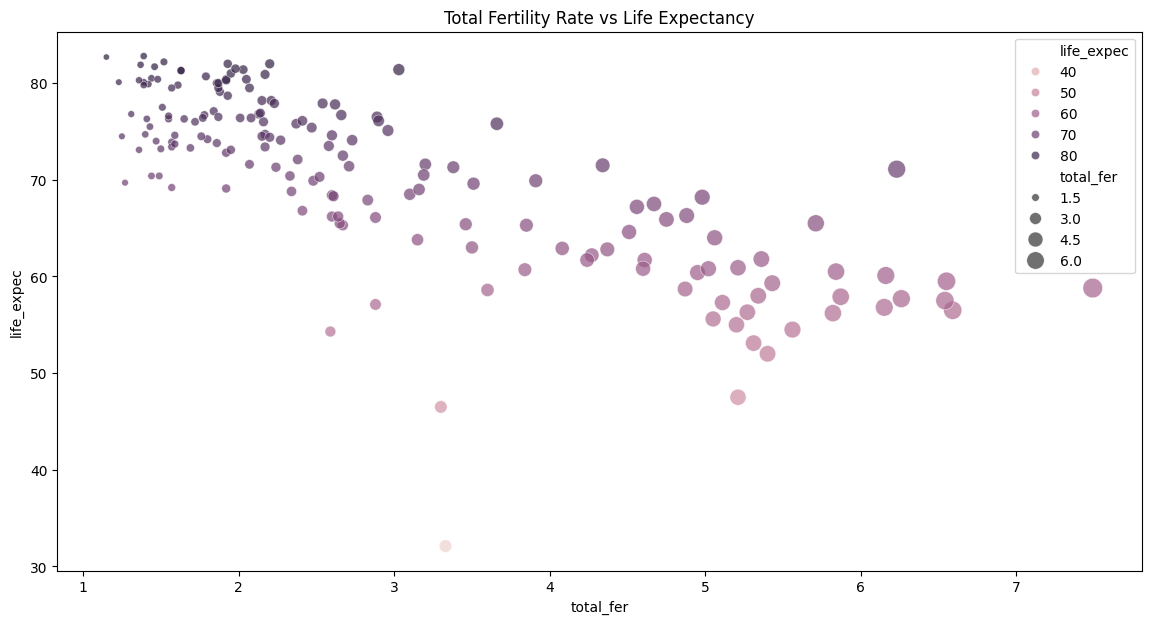

In [18]:
plt.figure(figsize=(14,7))
sns.scatterplot(data=data, x='total_fer', y='life_expec', hue='life_expec' , alpha=0.7 , size='total_fer' , sizes=(20,200))
plt.title('Total Fertility Rate vs Life Expectancy')
plt.show()

#### Checking for Outliers

In [19]:
num.shape

(167, 9)

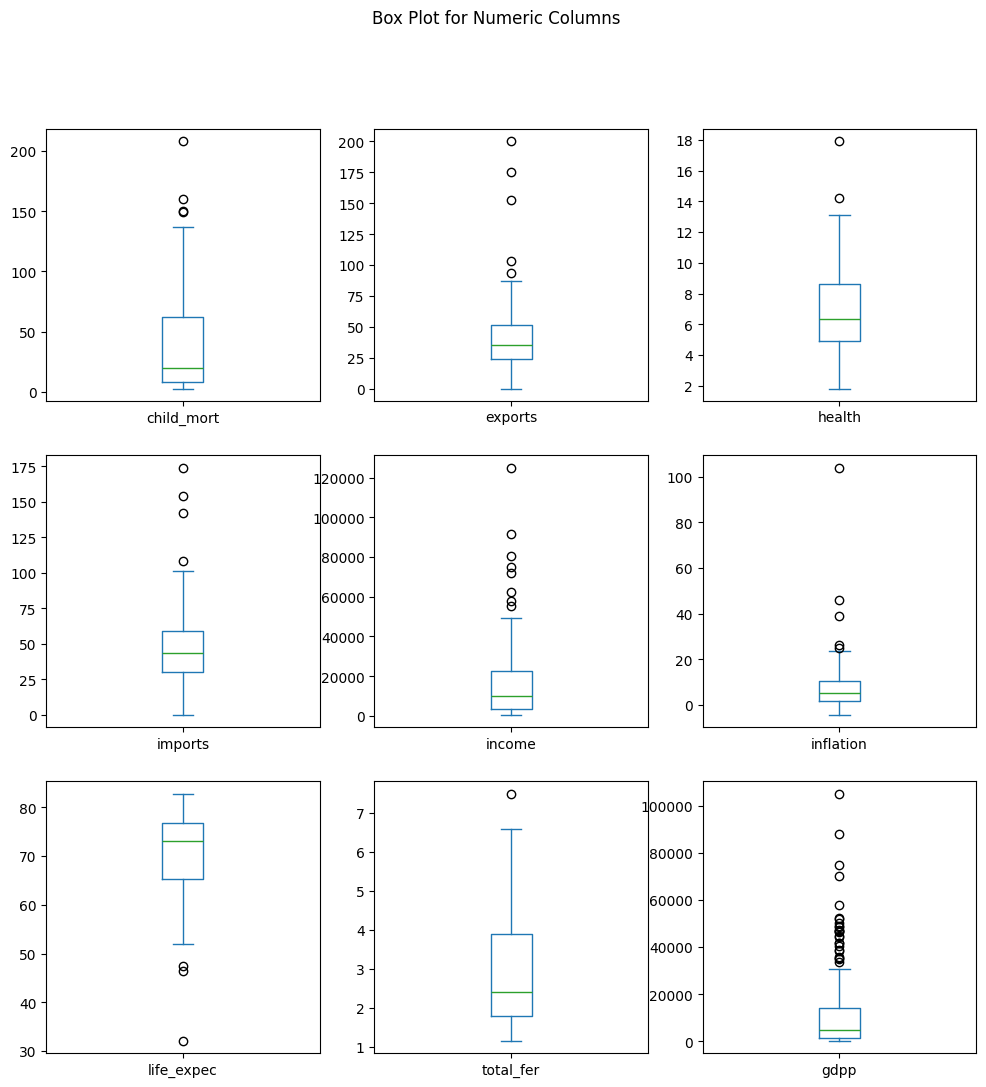

In [20]:
num.plot(kind="box", subplots=True, layout=(3,3), figsize=(12, 12))
plt.suptitle("Box Plot for Numeric Columns")
plt.show()

In [21]:
for col in num.columns:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    data[col] = np.where(data[col] < lower_bound, lower_bound, data[col])
    data[col] = np.where(data[col] > upper_bound, upper_bound, data[col])

In [22]:
def outlier_thresholds(dataframe, col_name, q1=0.25, q3=0.75):
    quartile1 = dataframe[col_name].quantile(q1)
    quartile3 = dataframe[col_name].quantile(q3)
    interquantile_range = quartile3 - quartile1
    up_limit = quartile3 + 1.5 * interquantile_range
    low_limit = quartile1 - 1.5 * interquantile_range
    return low_limit, up_limit

In [23]:
def check_outlier(dataframe, col_name):
    low_limit, up_limit = outlier_thresholds(dataframe, col_name)
    if dataframe[(dataframe[col_name] > up_limit) | (dataframe[col_name] < low_limit)].any(axis=None):
        return True
    else:
        return False

In [24]:
data.columns

Index(['country', 'child_mort', 'exports', 'health', 'imports', 'income',
       'inflation', 'life_expec', 'total_fer', 'gdpp'],
      dtype='object')

In [25]:
num

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200
...,...,...,...,...,...,...,...,...,...
162,29.2,46.6,5.25,52.7,2950,2.62,63.0,3.50,2970
163,17.1,28.5,4.91,17.6,16500,45.90,75.4,2.47,13500
164,23.3,72.0,6.84,80.2,4490,12.10,73.1,1.95,1310
165,56.3,30.0,5.18,34.4,4480,23.60,67.5,4.67,1310


In [26]:
for col in num.columns:
    print(check_outlier(data, col))

False
False
False
False
False
False
False
False
False


Sorting Data

In [27]:
Selected_Columns = data[['country', 'income', 'gdpp']]

In [28]:
Sorted_Data = Selected_Columns.sort_values(by=['income', 'gdpp'], ascending=False)

In [29]:
colors = ['#1f2b1d', '#2a3d2d', '#3b5b42', '#5a7f66', '#789f87', '#a8c8b1', '#d1e2d3', '#f2f5ea']

In [30]:
Top_Countries = Sorted_Data.head(15)

Text(0, 0.5, 'Country')

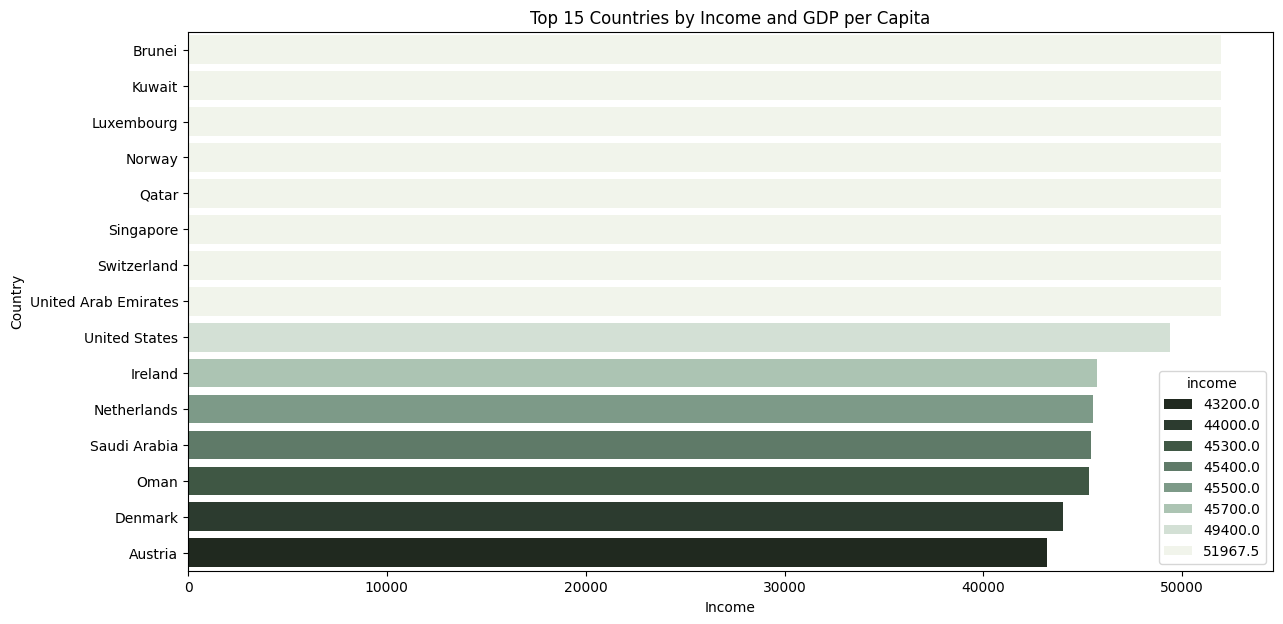

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 7))
sns.barplot(x='income', y='country', data=Top_Countries, hue='income', palette=colors)
plt.title('Top 15 Countries by Income and GDP per Capita')
plt.xlabel('Income')
plt.ylabel('Country')

15 Ülke Gelir ve Kişi Başına GSYİH Sıralaması

Açıklama:
Grafik, gelir ve kişi başına GSYİH'ye göre sıralanan en yüksek 15 ülkeyi yatay çubuk grafiği ile göstermektedir.

Önemli Gözlemler:

Gelir açısından en yüksek sıralamadaki ülkeler Brunei, Kuveyt ve Lüksemburg'dur.
En üst sıralardaki ülkelerin çoğu Avrupa ve Orta Doğu'dan gelmektedir.
Sonuç:
Grafik, yüksek kişi başına GSYİH’ye sahip ülkelerin genellikle güçlü ekonomilere ve yüksek yaşam standartlarına sahip olduğunu, bu durumun özellikle Avrupa ve Orta Doğu gibi belirli bölgelerde yoğunlaştığını vurgulamaktadır.

Top 10 Countries by Lowest Child Mortality and Highest income

In [32]:
Select_Columns = data[['country', 'income', 'child_mort']]

In [33]:
Sorted = Select_Columns.sort_values(by='child_mort', ascending=True)

In [34]:
First_10_Countries = Sorted.head(10)

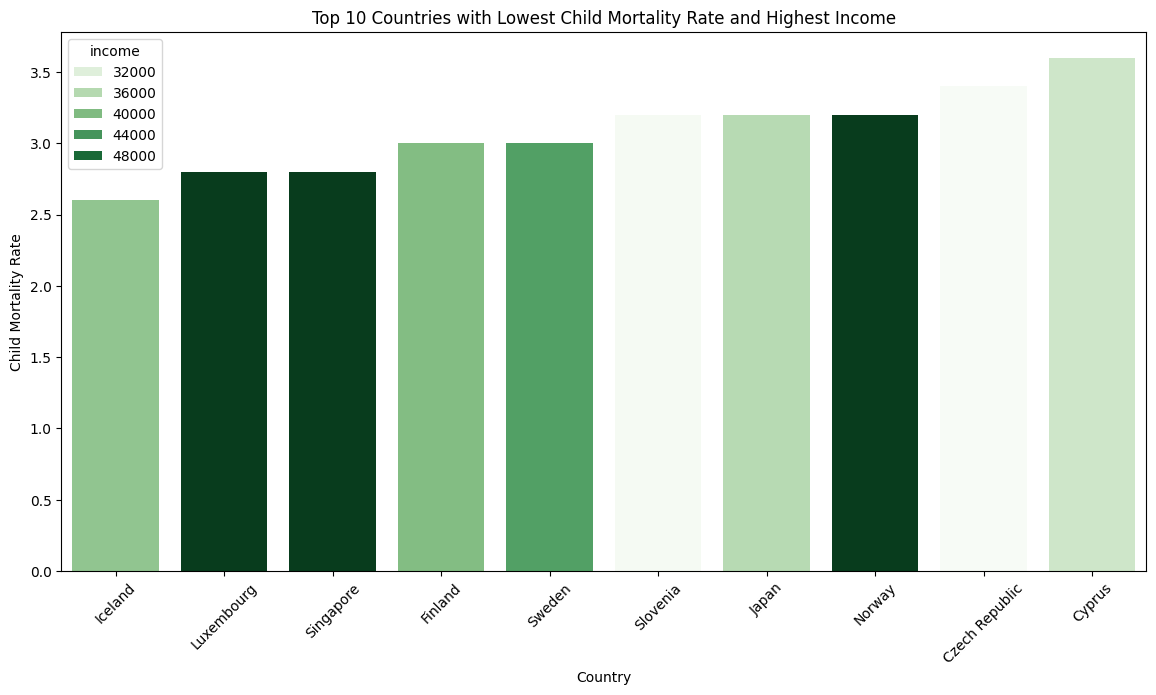

In [35]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 7))
sns.barplot(x='country', y='child_mort', data=First_10_Countries, hue='income', palette='Greens')

plt.title('Top 10 Countries with Lowest Child Mortality Rate and Highest Income')
plt.xlabel('Country')
plt.ylabel('Child Mortality Rate')
plt.xticks(rotation=45)
plt.show()

En Düşük Çocuk Ölümü ve En Yüksek Gelir Seviyesine Sahip 10 Ülke

Açıklama:
Grafik, en düşük çocuk ölüm oranlarına ve en yüksek gelir seviyelerine sahip 10 ülkeyi göstermektedir. Her ülke için gelir değerleri belirtilmiştir.

Ana Gözlemler:

En düşük çocuk ölüm oranlarına ve en yüksek gelir seviyelerine sahip ülkeler arasında Lüksemburg, Norveç ve Singapur bulunmaktadır.
En üst sıralardaki ülkelerin çoğu Avrupa’dan, bazıları ise Asya’dandır.
Bu ülkeler arasındaki gelir seviyeleri yaklaşık 32,000 
i
l
e
48
,
000
ile48,000 arasında değişmektedir.
Sonuç:
Grafik, daha yüksek gelir seviyeleri ile daha düşük çocuk ölüm oranları arasında güçlü bir ilişki olduğunu göstermektedir. Daha zengin ülkelerin genellikle çocuk ölüm oranlarını düşüren daha iyi sağlık sistemlerine sahip olduğu görülmektedir.

In [36]:
copy_data = data.copy()

In [37]:
copy_data = copy_data.drop(columns=['country'])

Feature Scaling

In [38]:
#from sklearn.preprocessing import StandardScaler

#scaler = StandardScaler()
#scaler

In [39]:
#scaled_data = scaler.fit_transform(copy_data)

In [40]:
from sklearn.preprocessing import RobustScaler  # StandardScaler yerine
scaler = RobustScaler()
scaled_data = scaler.fit_transform(copy_data)

Standard Scaler ve Robust Scaler farkı
    - StandardScaler verileri normal dağılıma göre ölçeklendirirken, RobustScaler aykırı değerlerden daha az etkilenen medyan ve çeyrekler arası aralık kullanarak ölçeklendirme yapar

Küme Sayısını Belirlemenin Optimal Yöntemleri

Elbow method

In [41]:
from sklearn.cluster import KMeans

inertia_values = []

for i in range(2,11) :
  model = KMeans(n_clusters=i , random_state=42)
  model.fit(num)
  inertia_values.append(model.inertia_)

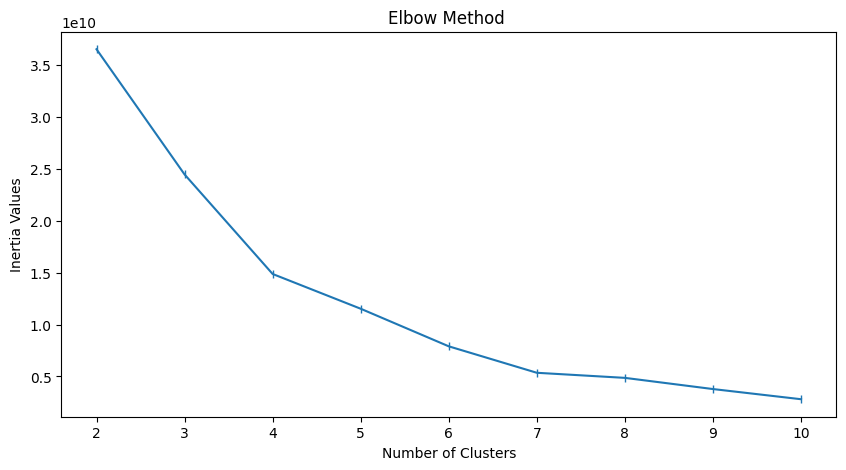

In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(range(2,11), inertia_values , marker='|')

plt.xlabel('Number of Clusters')
plt.ylabel('Inertia Values')
plt.title('Elbow Method ')

plt.show()

Silhouette Score Method

In [43]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

silhouette_scores = []

for k in range(2, 11):
  model = KMeans(n_clusters=k, random_state=42, n_init=10)
  model.fit(scaled_data)
  score = silhouette_score(scaled_data, model.labels_)
  silhouette_scores.append(score)

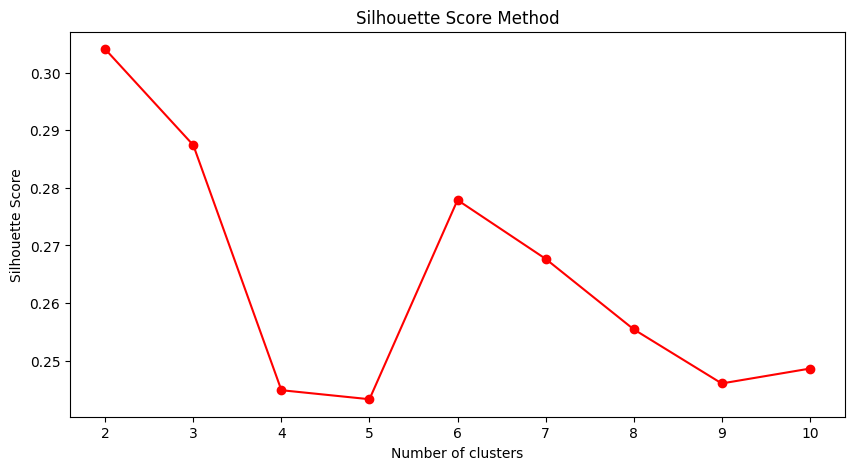

In [44]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(range(2,11), silhouette_scores, marker='o', color='red')

plt.xlabel('Number of clusters')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score Method')

plt.show()

Creating the Model

Creating a KMeans Model with the Selected Number of Clusters

In [45]:
from sklearn.cluster import KMeans

kmean = KMeans(n_clusters=2, random_state=42)
kmean

KMeans(n_clusters=2, random_state=42)

In [46]:
kmean.fit(num)

KMeans(n_clusters=2, random_state=42)

In [47]:
labels = kmean.labels_

In [48]:
data['Cluster'] = labels


Analyzing Cluster Characteristics and Interpreting the Results

Assigning Cluster Labels to the Numeric Data

In [49]:
copy_data['Cluster'] = labels

In [50]:
cluster_summary = copy_data.groupby('Cluster').mean().T
cluster_summary

Cluster,0,1
child_mort,45.308148,5.593750
exports,37.131474,49.719531
health,6.419704,8.365625
imports,46.556414,42.932812
income,9602.688889,42579.375000
inflation,7.826681,3.852000
life_expec,68.427778,80.096875
total_fer,3.195241,1.889687
gdpp,5348.992593,31454.687500


In [51]:
labels_dict = {
    0:'Düşük Gelişmişlik Düzeyi',
    1:'Yüksek Gelişmişlik Düzeyi',
    2:'Orta Gelişmişlik Düzeyi'
}

data['Cluster'] = data['Cluster'].map(labels_dict)

In [52]:
High_Income_Good_Health = data[data['Cluster']=='Yüksek Gelişmişlik Düzeyi']

print("Yüksek Gelişmişlik Düzeyi':")
print(High_Income_Good_Health['country'])
print(f"\nNumber of countries in this category: {High_Income_Good_Health.shape[0]}")

Yüksek Gelişmişlik Düzeyi':
7                 Australia
8                   Austria
11                  Bahrain
15                  Belgium
23                   Brunei
29                   Canada
42                   Cyprus
44                  Denmark
53                  Finland
54                   France
58                  Germany
60                   Greece
68                  Iceland
73                  Ireland
74                   Israel
75                    Italy
77                    Japan
82                   Kuwait
91               Luxembourg
110             Netherlands
111             New Zealand
114                  Norway
115                    Oman
123                   Qatar
128            Saudi Arabia
133               Singapore
139                   Spain
144                  Sweden
145             Switzerland
157    United Arab Emirates
158          United Kingdom
159           United States
Name: country, dtype: object

Number of countries in this category: 32


In [53]:
Moderate_Health_Issues = data[data['Cluster']=='Orta Gelişmişlik Düzeyi']

print("Orta Gelişmişlik Düzeyi:")
print(Moderate_Health_Issues['country'])
print(f"\nNumber of countries in this category: {Moderate_Health_Issues.shape[0]}")

Orta Gelişmişlik Düzeyi:
Series([], Name: country, dtype: object)

Number of countries in this category: 0


In [54]:
Severe_Health_Issues = data[data['Cluster']=='Düşük Gelişmişlik Düzeyi']

print("Düşük Gelişmişlik Düzeyi:")
print(Severe_Health_Issues['country'])
print(f"\nNumber of countries in this category: {Severe_Health_Issues.shape[0]}")

Düşük Gelişmişlik Düzeyi:
0              Afghanistan
1                  Albania
2                  Algeria
3                   Angola
4      Antigua and Barbuda
              ...         
162                Vanuatu
163              Venezuela
164                Vietnam
165                  Yemen
166                 Zambia
Name: country, Length: 135, dtype: object

Number of countries in this category: 135


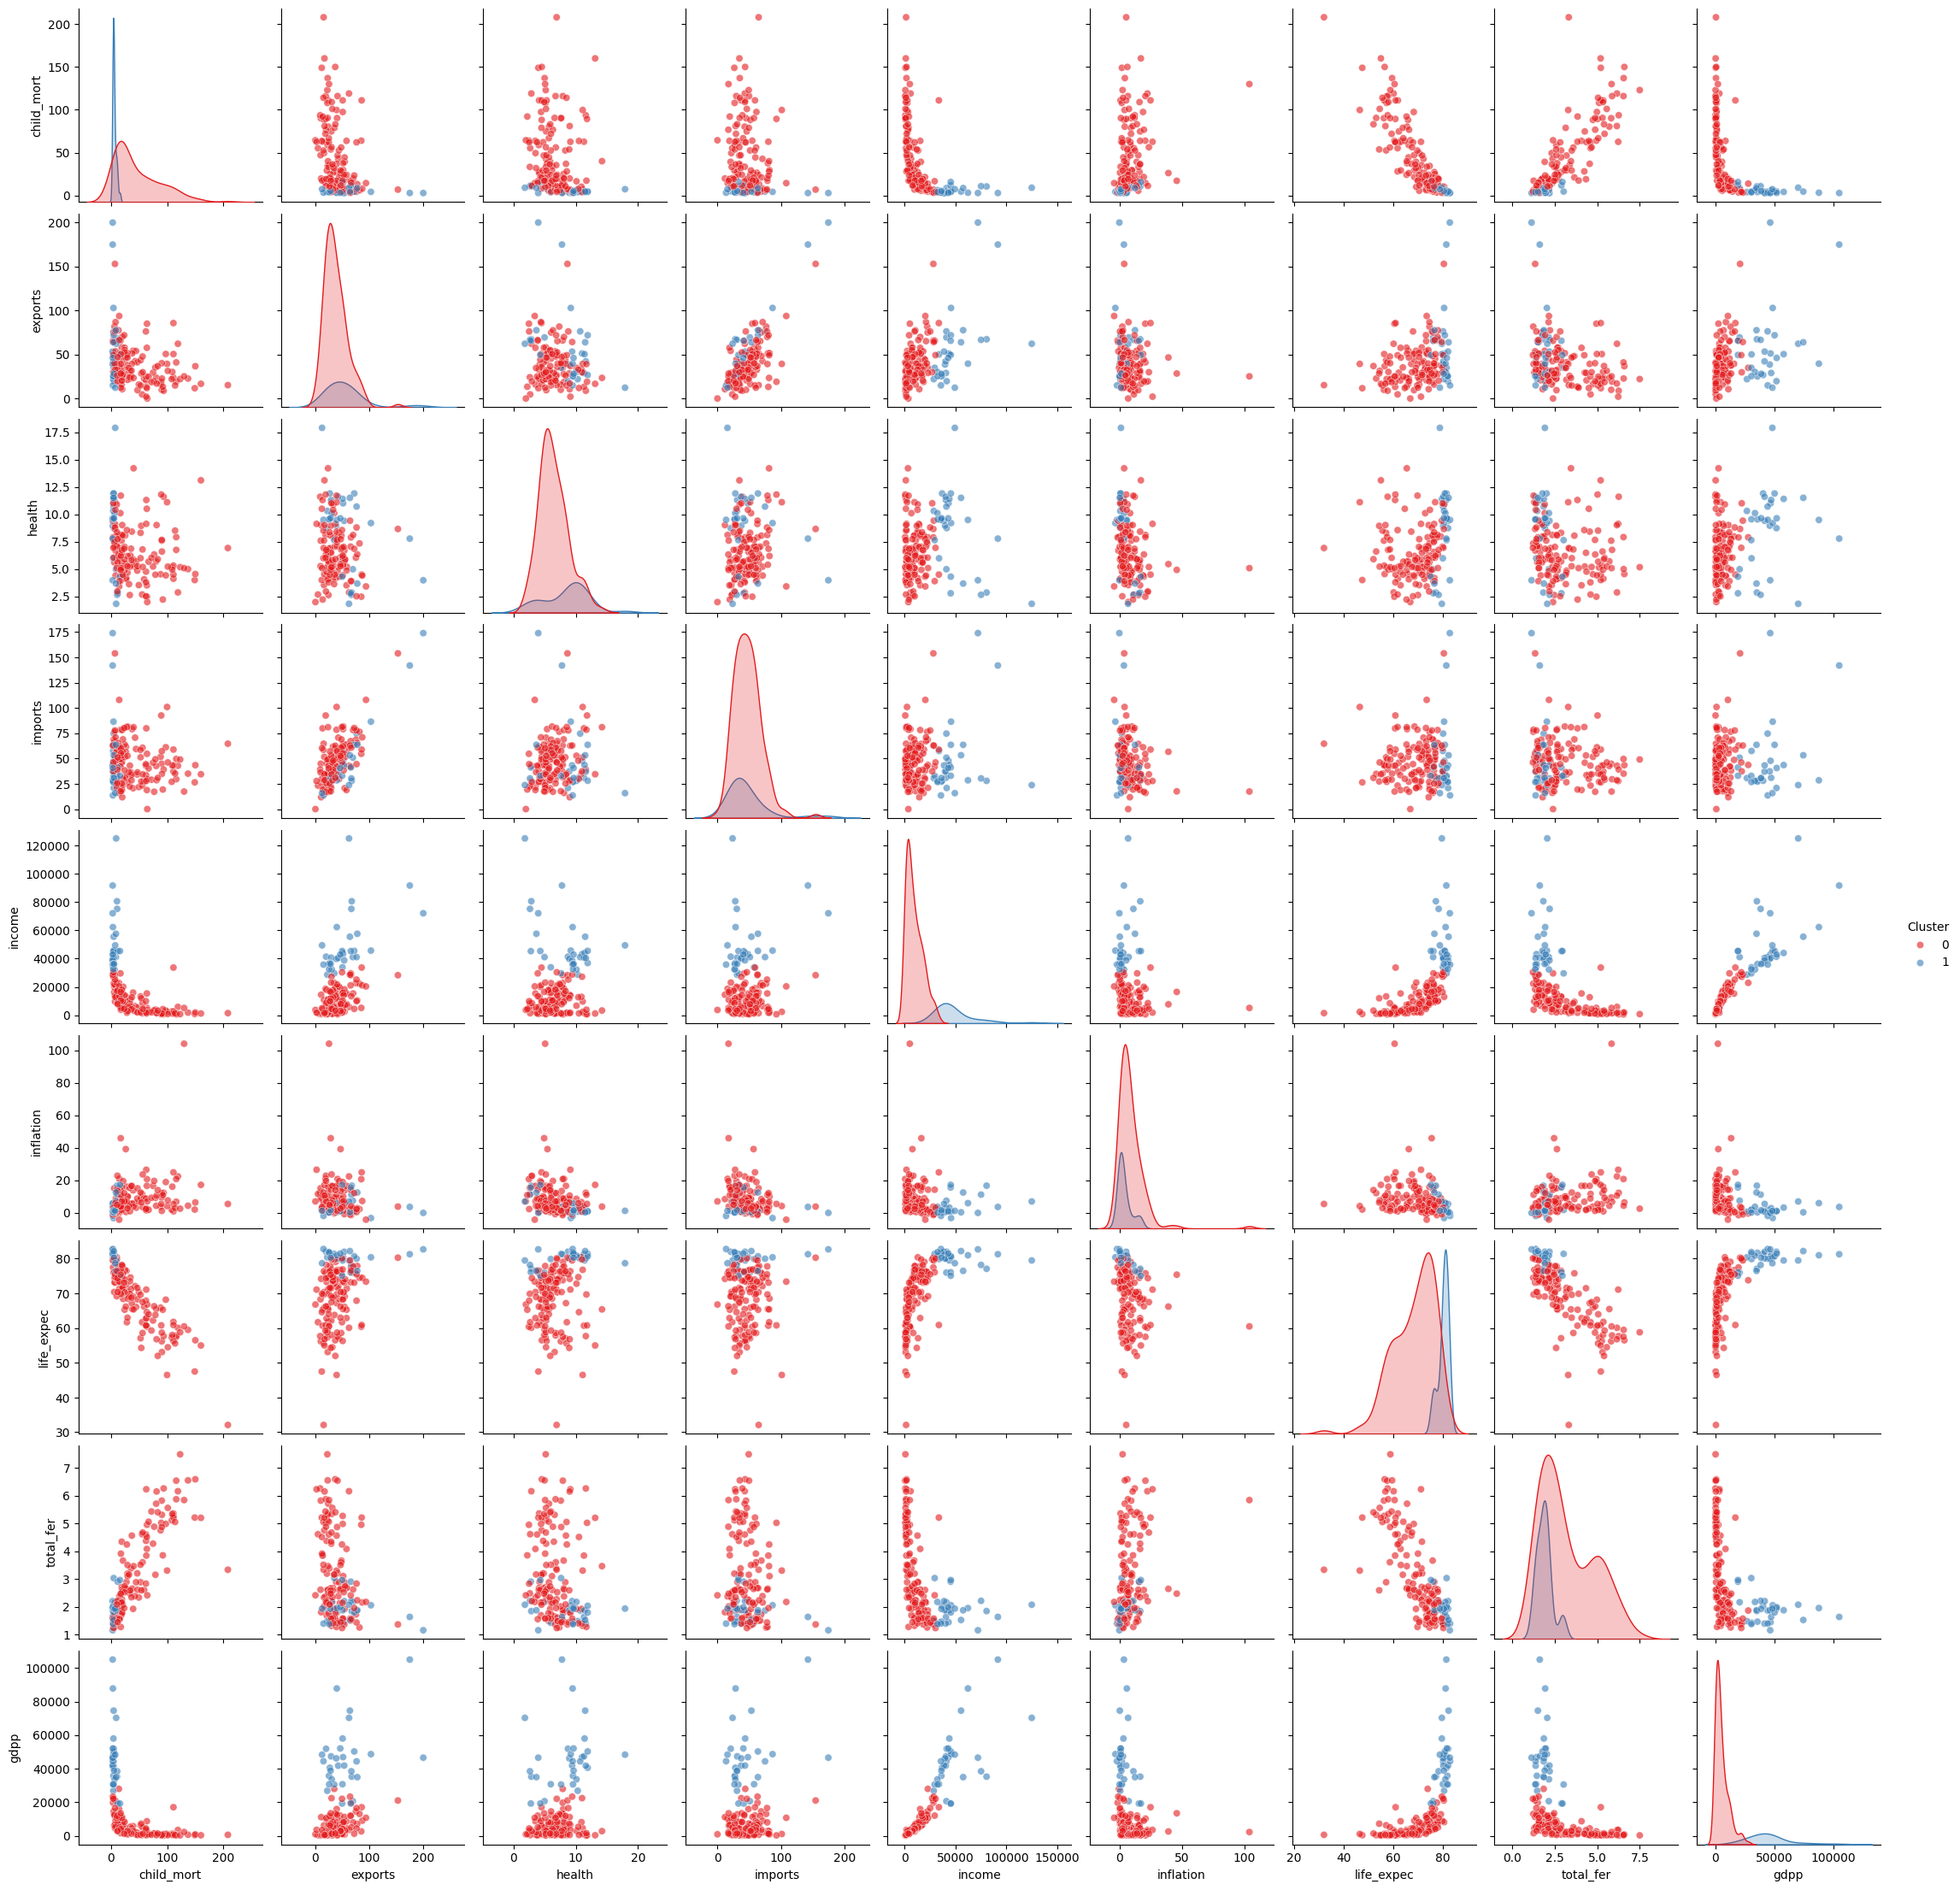

In [55]:
num['Cluster'] = kmean.labels_

sns.pairplot(num, 
            hue='Cluster', 
            palette='Set1',
            plot_kws={'alpha': 0.6})
plt.show()

In [56]:
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

silhouette_avg = silhouette_score(num, kmean.labels_)
calinski_score = calinski_harabasz_score(num, kmean.labels_)
davies_score = davies_bouldin_score(num, kmean.labels_)

print("K-means Kümeleme Performans Metrikleri:")
print("-" * 40)
print(f"Silhouette Skoru: {silhouette_avg:.3f}")
print(f"Calinski-Harabasz Skoru: {calinski_score:.3f}")
print(f"Davies-Bouldin Skoru: {davies_score:.3f}")

K-means Kümeleme Performans Metrikleri:
----------------------------------------
Silhouette Skoru: 0.726
Calinski-Harabasz Skoru: 365.569
Davies-Bouldin Skoru: 0.519


- Silhoutte -> 0.50 - 0.75 -> İyi kümeleme (Mükemmele çok yakın)
- Calinski -> 100+ -> Çok iyi kümeleme
- Davies -> 0.4 - 0.7 -> İyi kümeleme

In [57]:
# Her küme için ayrı ayrı silhouette skorlarını hesaplama
from sklearn.metrics import silhouette_samples
silhouette_vals = silhouette_samples(num, kmean.labels_)

# Kümelere göre ortalama silhouette skorları
for i in range(kmean.n_clusters):
    cluster_silhouette = silhouette_vals[kmean.labels_ == i].mean()
    print(f"Küme {i} için ortalama Silhouette skoru: {cluster_silhouette:.3f}")

Küme 0 için ortalama Silhouette skoru: 0.791
Küme 1 için ortalama Silhouette skoru: 0.448


# Hiyerarşik Kümeleme

In [58]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

In [59]:
# Test edilecek parametreler
linkage_methods = ['ward', 'complete', 'average', 'single']
n_clusters_range = range(2, 8)

In [60]:
results = []

In [61]:
# Farklı linkage metodları için test
for linkage_method in linkage_methods:
    print(f"\n{linkage_method.capitalize()} Linkage Testi:")
    print("-" * 40)
    
    silhouette_scores = []
    calinski_scores = []
    davies_scores = []
    
    for n_clusters in n_clusters_range:
        clustering = AgglomerativeClustering(
            n_clusters=n_clusters,
            linkage=linkage_method
        )
        labels = clustering.fit_predict(num)
        
        silhouette = silhouette_score(num, labels)
        calinski = calinski_harabasz_score(num, labels)
        davies = davies_bouldin_score(num, labels)
        
        silhouette_scores.append(silhouette)
        calinski_scores.append(calinski)
        davies_scores.append(davies)
        
        results.append({
            'n_clusters': n_clusters,
            'linkage': linkage_method,
            'silhouette': silhouette,
            'calinski': calinski,
            'davies': davies
        })
        
        print(f"\nKüme Sayısı: {n_clusters}")
        print(f"Silhouette Skoru: {silhouette:.3f}")
        print(f"Calinski-Harabasz Skoru: {calinski:.3f}")
        print(f"Davies-Bouldin Skoru: {davies:.3f}")


Ward Linkage Testi:
----------------------------------------

Küme Sayısı: 2
Silhouette Skoru: 0.723
Calinski-Harabasz Skoru: 322.465
Davies-Bouldin Skoru: 0.512

Küme Sayısı: 3
Silhouette Skoru: 0.596
Calinski-Harabasz Skoru: 309.294
Davies-Bouldin Skoru: 0.671

Küme Sayısı: 4
Silhouette Skoru: 0.609
Calinski-Harabasz Skoru: 373.544
Davies-Bouldin Skoru: 0.685

Küme Sayısı: 5
Silhouette Skoru: 0.613
Calinski-Harabasz Skoru: 362.017
Davies-Bouldin Skoru: 0.684

Küme Sayısı: 6
Silhouette Skoru: 0.615
Calinski-Harabasz Skoru: 375.810
Davies-Bouldin Skoru: 0.510

Küme Sayısı: 7
Silhouette Skoru: 0.539
Calinski-Harabasz Skoru: 437.430
Davies-Bouldin Skoru: 0.526

Complete Linkage Testi:
----------------------------------------

Küme Sayısı: 2
Silhouette Skoru: 0.739
Calinski-Harabasz Skoru: 82.143
Davies-Bouldin Skoru: 0.461

Küme Sayısı: 3
Silhouette Skoru: 0.708
Calinski-Harabasz Skoru: 342.273
Davies-Bouldin Skoru: 0.627

Küme Sayısı: 4
Silhouette Skoru: 0.704
Calinski-Harabasz Skoru: 

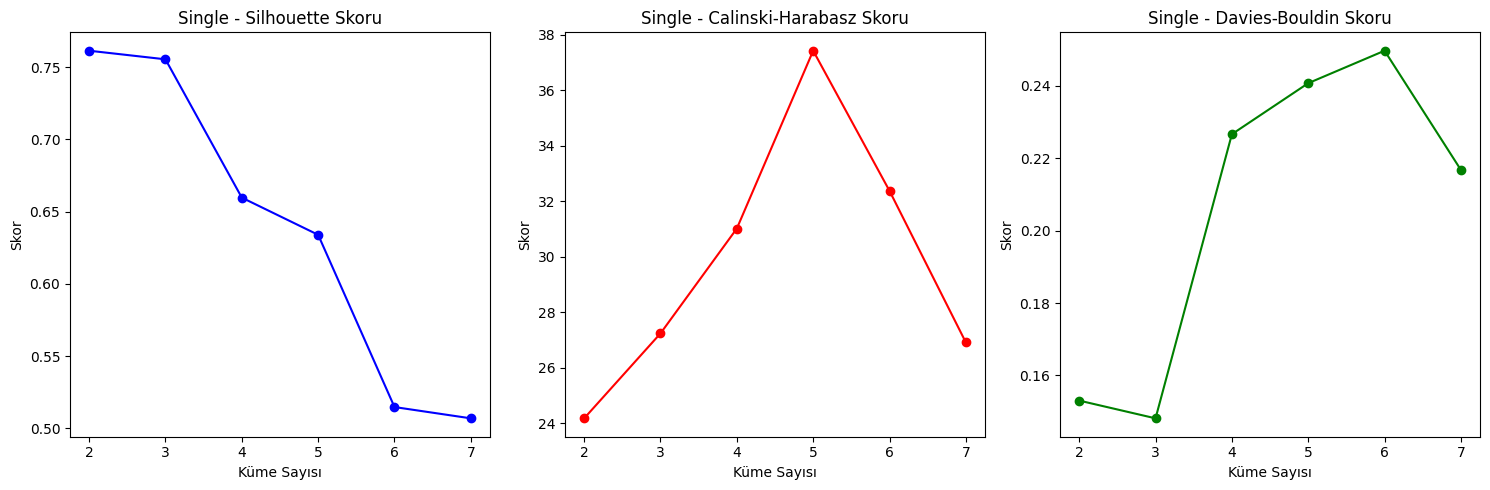

In [62]:
plt.figure(figsize=(15, 5))

plt.subplot(131)
plt.plot(list(n_clusters_range), silhouette_scores, 'bo-')
plt.title(f'{linkage_method.capitalize()} - Silhouette Skoru')
plt.xlabel('Küme Sayısı')
plt.ylabel('Skor')

plt.subplot(132)
plt.plot(list(n_clusters_range), calinski_scores, 'ro-')
plt.title(f'{linkage_method.capitalize()} - Calinski-Harabasz Skoru')
plt.xlabel('Küme Sayısı')
plt.ylabel('Skor')

plt.subplot(133)
plt.plot(list(n_clusters_range), davies_scores, 'go-')
plt.title(f'{linkage_method.capitalize()} - Davies-Bouldin Skoru')
plt.xlabel('Küme Sayısı')
plt.ylabel('Skor')

plt.tight_layout()
plt.show()

In [63]:
best_silhouette = max(results, key=lambda x: x['silhouette'])
best_calinski = max(results, key=lambda x: x['calinski'])
best_davies = min(results, key=lambda x: x['davies'])

In [64]:
print("\nEn İyi Sonuçlar:")
print("-" * 40)
print("\nEn Yüksek Silhouette Skoru:")
print(f"Linkage: {best_silhouette['linkage']}")
print(f"Küme Sayısı: {best_silhouette['n_clusters']}")
print(f"Silhoute Skor: {best_silhouette['silhouette']:.3f}")
print(f"Calinski - Harabasz Skor: {best_calinski['calinski']:.3f}")
print(f"Davies - Bouldin Skor: {best_davies['davies']:.3f}")


En İyi Sonuçlar:
----------------------------------------

En Yüksek Silhouette Skoru:
Linkage: single
Küme Sayısı: 2
Silhoute Skor: 0.761
Calinski - Harabasz Skor: 437.430
Davies - Bouldin Skor: 0.148


- Silhoutte Skoru: 0.75 - 1.00 -> Mükemmel Kümeleme
- Calinski - Harabasz Skoru: 100+ -> Çok iyi kümeleme
- Davies - Bouldin SkoruÇ 0 - 0.4 -> Çok iyi kümeleme

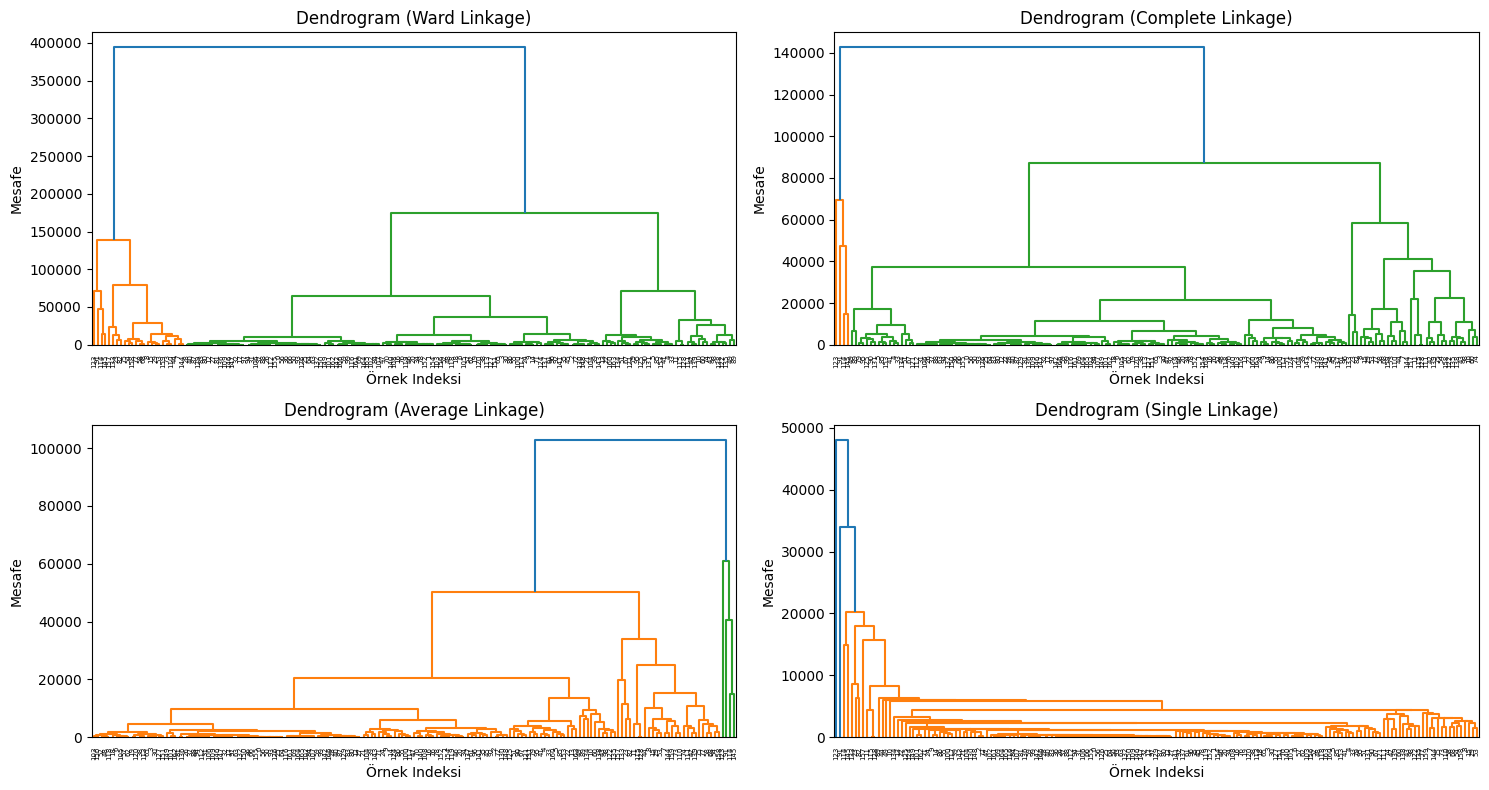

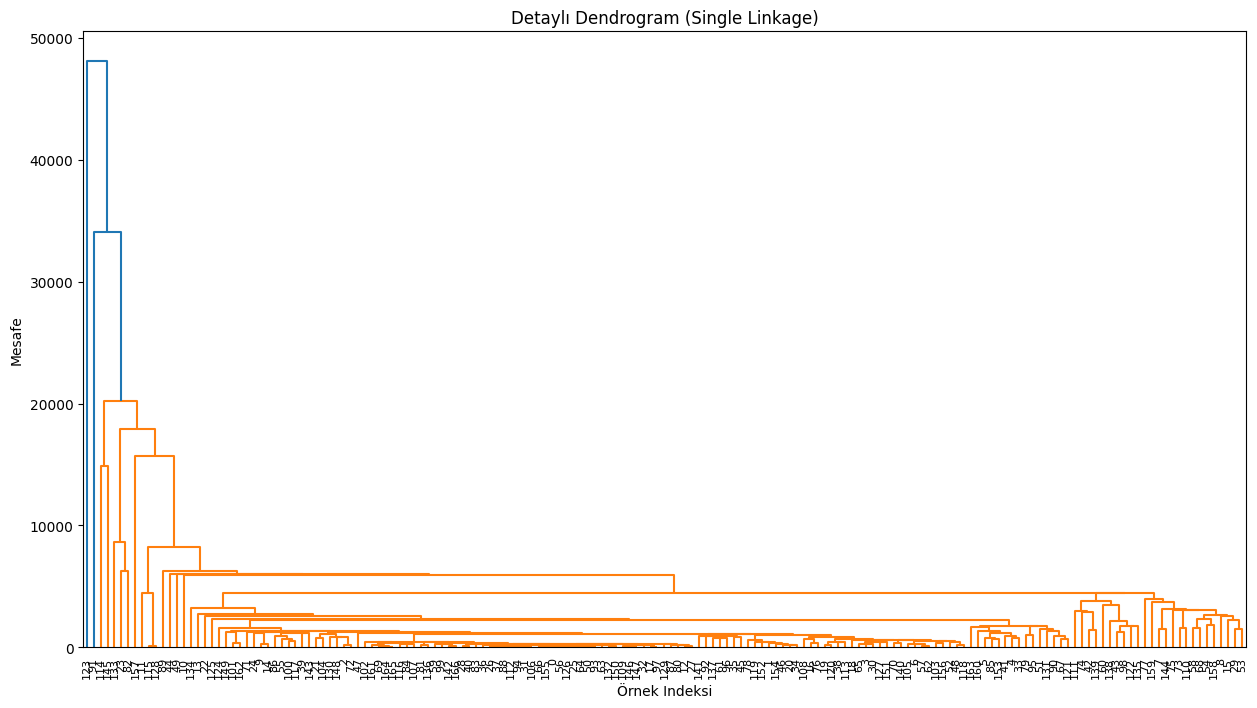

In [65]:
plt.figure(figsize=(15, 8))

for idx, method in enumerate(linkage_methods, 1):
    plt.subplot(2, 2, idx)

    linkage_matrix = linkage(num, method=method)
    
    dendrogram(linkage_matrix)
    
    plt.title(f'Dendrogram ({method.capitalize()} Linkage)')
    plt.xlabel('Örnek Indeksi')
    plt.ylabel('Mesafe')
    
plt.tight_layout()
plt.show()


plt.figure(figsize=(15, 8))
best_linkage_matrix = linkage(num, method=best_silhouette['linkage'])

dendrogram(best_linkage_matrix, 
          leaf_rotation=90,
          leaf_font_size=8,
          color_threshold=0.7*max(best_linkage_matrix[:,2]))

plt.title(f'Detaylı Dendrogram ({best_silhouette["linkage"].capitalize()} Linkage)')
plt.xlabel('Örnek Indeksi')
plt.ylabel('Mesafe')
plt.show()

In [66]:
best_model = AgglomerativeClustering(
    n_clusters=best_silhouette['n_clusters'],
    linkage=best_silhouette['linkage']
)
best_labels = best_model.fit_predict(num)


In [67]:
data_with_clusters = data.copy()
data_with_clusters['Cluster'] = best_labels

In [68]:
print("\nKüme İstatistikleri:")
for cluster in np.unique(best_labels):
    print(f"\nKüme {cluster} İstatistikleri:")
    if cluster == -1:
        print("(Gürültü Noktaları)")
    cluster_stats = data_with_clusters[data_with_clusters['Cluster'] == cluster][num.columns].mean()
    print(cluster_stats)


Küme İstatistikleri:

Küme 0 İstatistikleri:
child_mort       37.871084
exports          39.406470
health            6.822590
imports          45.994975
income        15704.430723
inflation         7.065578
life_expec       70.610542
total_fer         2.950346
gdpp          10214.060241
Cluster           0.000000
dtype: float64

Küme 1 İstatistikleri:
child_mort        9.00
exports          62.30
health            1.81
imports          23.80
income        51967.50
inflation         6.98
life_expec       79.50
total_fer         2.07
gdpp          33130.00
Cluster           1.00
dtype: float64


# DBSCAN

In [69]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt

In [70]:
# En uygun epsilon değerini bulmak için KNN grafiği
neighbors = NearestNeighbors(n_neighbors=2)
neighbors_fit = neighbors.fit(num)
distances, indices = neighbors_fit.kneighbors(num)
distances = np.sort(distances, axis=0)
distances = distances[:,1]

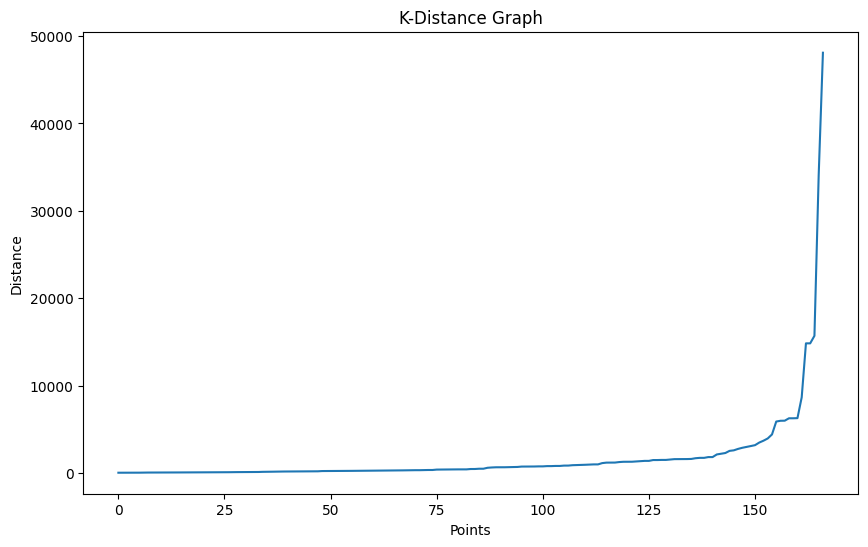

In [71]:
plt.figure(figsize=(10, 6))
plt.plot(distances)
plt.title('K-Distance Graph')
plt.xlabel('Points')
plt.ylabel('Distance')
plt.show()

In [72]:
dbscan = DBSCAN(eps=1500, min_samples=6)
dbscan_labels = dbscan.fit_predict(num)

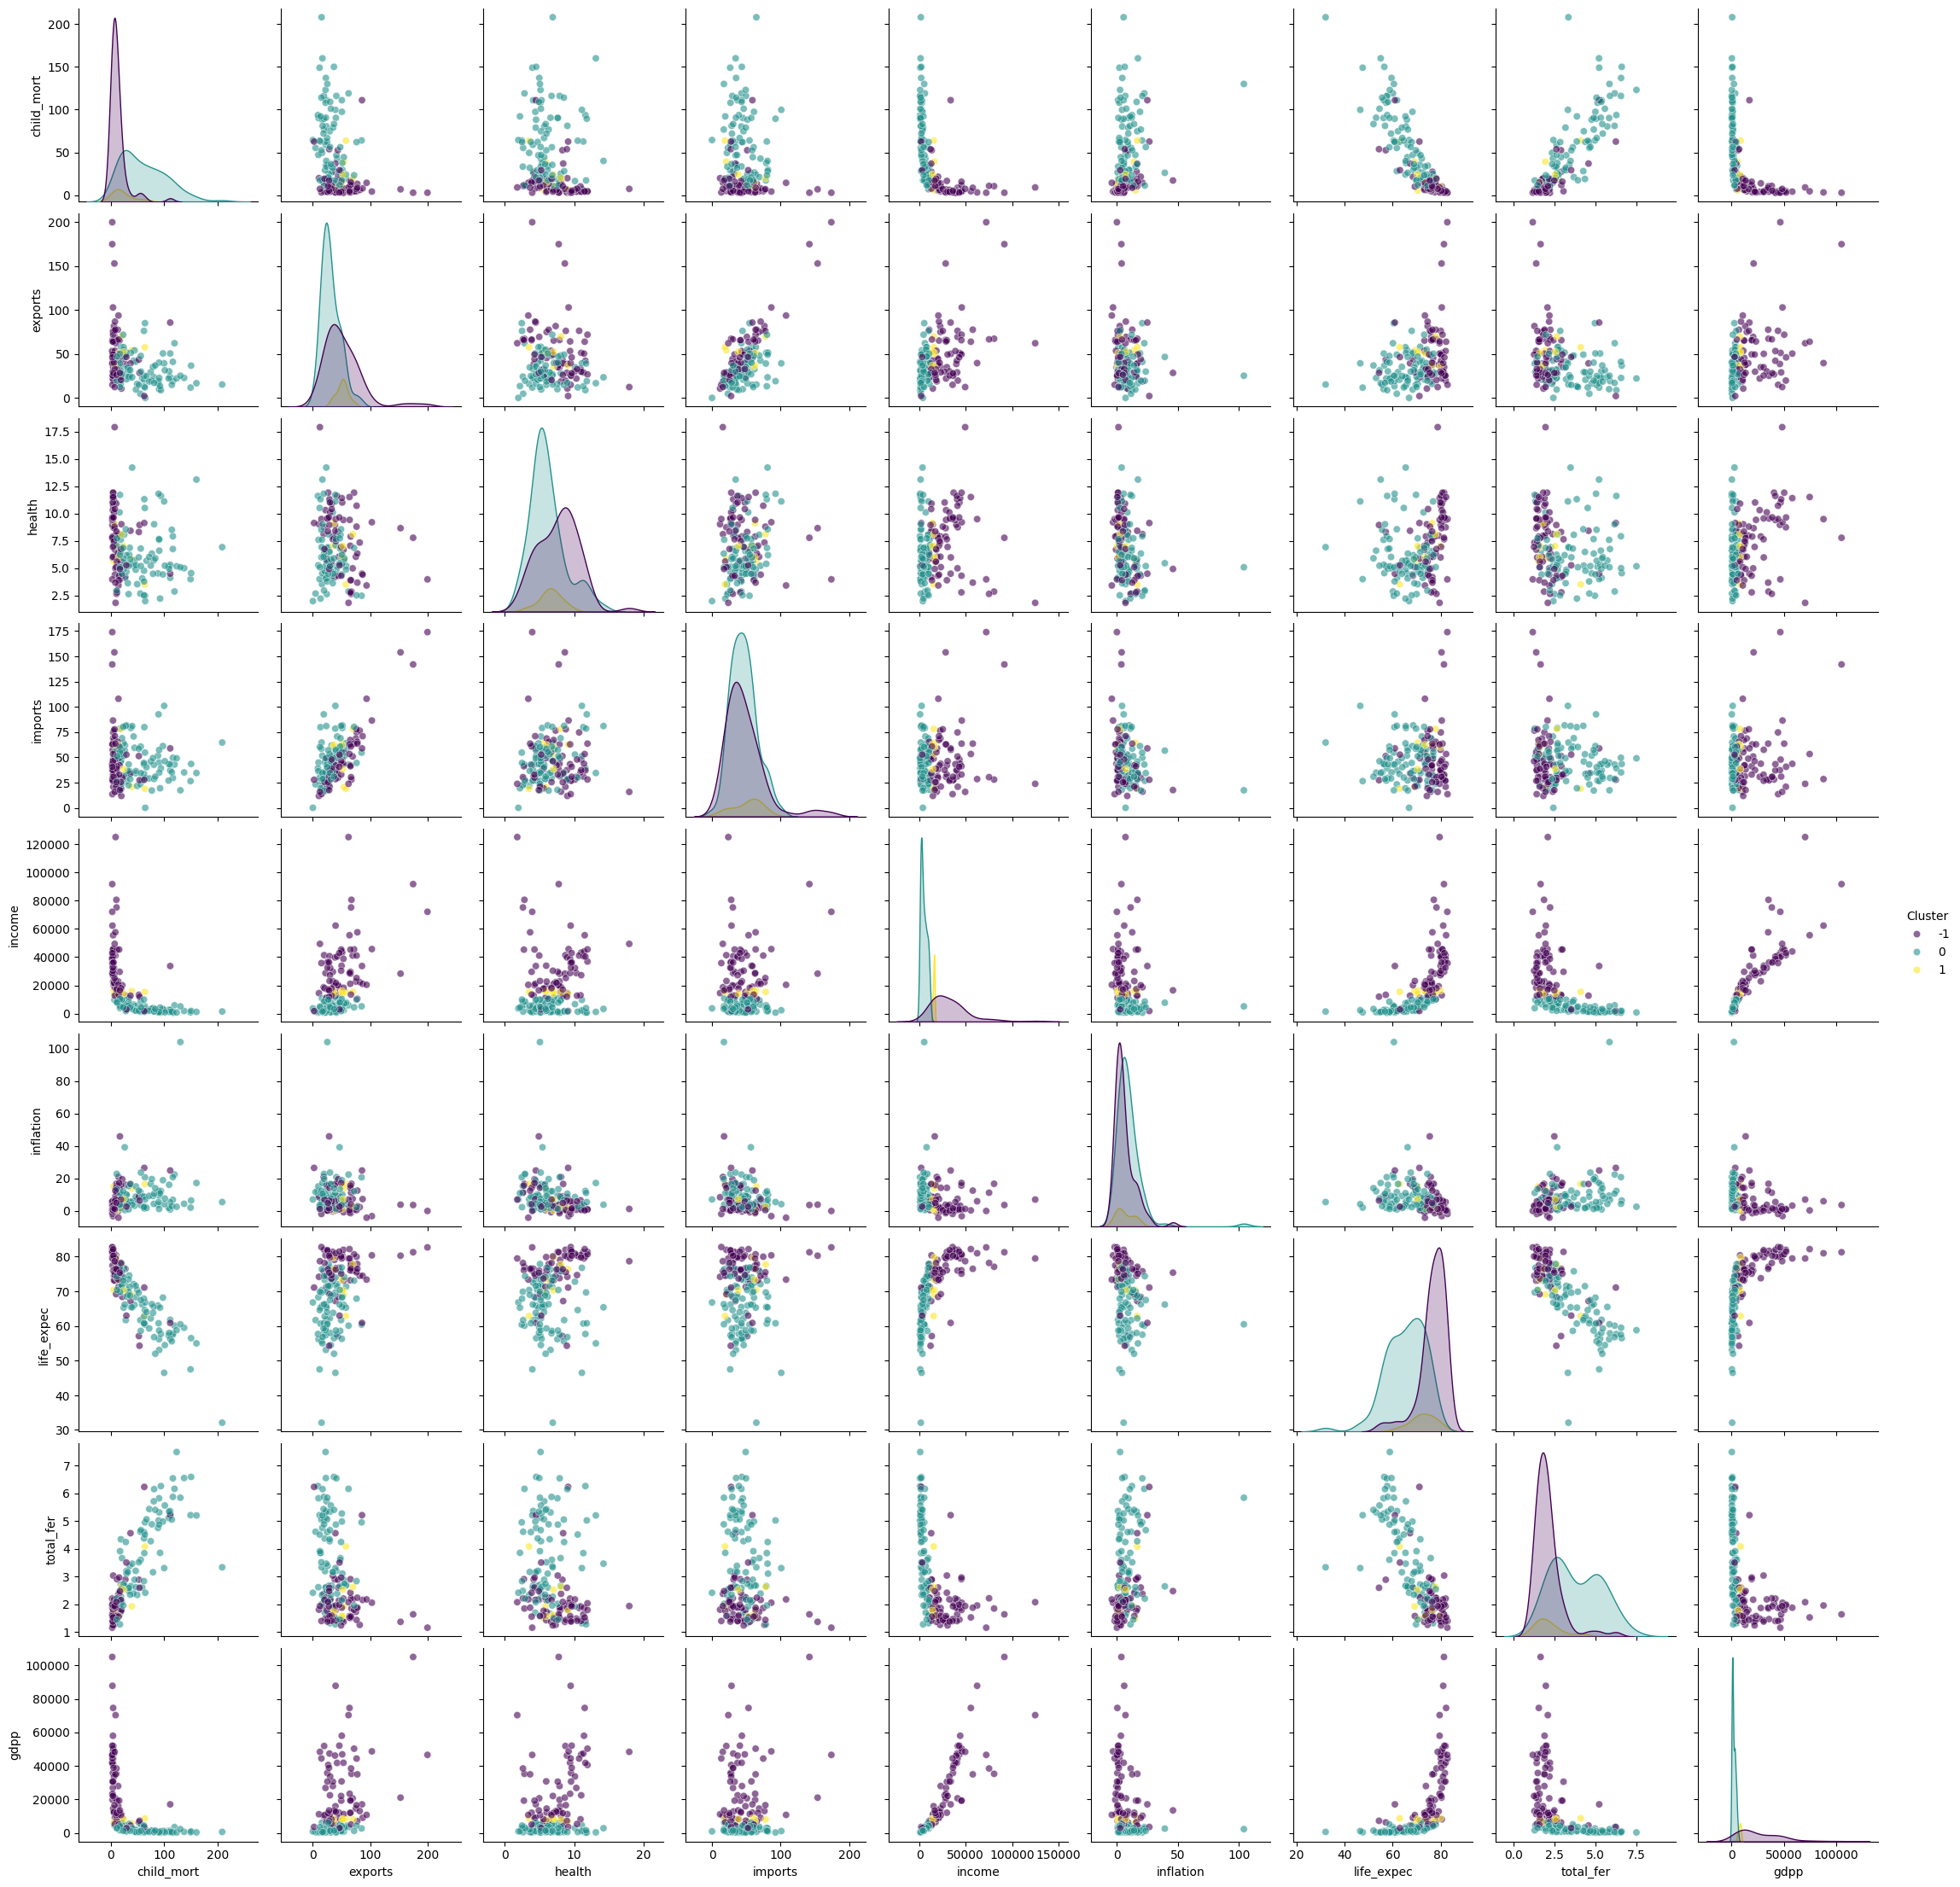

In [73]:
num_with_clusters = num.copy()
num_with_clusters['Cluster'] = dbscan_labels

sns.pairplot(num_with_clusters, 
            hue='Cluster', 
            palette='viridis',
            plot_kws={'alpha': 0.6})
plt.show()

In [74]:
valid_labels = dbscan_labels != -1

In [75]:
num[valid_labels]

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp,Cluster
0,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553,0
1,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090,0
3,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530,0
6,18.1,20.8,4.40,45.3,6700,7.77,73.3,1.69,3220,0
9,39.2,54.3,5.88,20.7,16000,13.80,69.1,1.92,5840,0
...,...,...,...,...,...,...,...,...,...,...
156,11.7,47.1,7.72,51.1,7820,13.40,70.4,1.44,2970,0
161,36.3,31.7,5.81,28.5,4240,16.50,68.8,2.34,1380,0
164,23.3,72.0,6.84,80.2,4490,12.10,73.1,1.95,1310,0
165,56.3,30.0,5.18,34.4,4480,23.60,67.5,4.67,1310,0


In [76]:
valid_labels = dbscan_labels != -1

print("\nDBSCAN Kümeleme Performans Metrikleri:")
print("-" * 40)
print(f"Silhouette Skoru: {silhouette_score(num[valid_labels], dbscan_labels[valid_labels]):.3f}")
print(f"Calinski-Harabasz Skoru: {calinski_harabasz_score(num[valid_labels], dbscan_labels[valid_labels]):.3f}")
print(f"Davies-Bouldin Skoru: {davies_bouldin_score(num[valid_labels], dbscan_labels[valid_labels]):.3f}")


DBSCAN Kümeleme Performans Metrikleri:
----------------------------------------
Silhouette Skoru: 0.614
Calinski-Harabasz Skoru: 98.743
Davies-Bouldin Skoru: 0.368


- Silhoutte Skoru: 0.5 - 0.75 aralığı -> İyi kümeleme
- Calinski - Harabasz Skoru: 100'e çok yakın -> Çok iyi seviyeye yakın
- Davies-Bouldin Skoru: 0 - 0.4 aralığı -> Çok iyi kümeleme

In [77]:
data_with_dbscan = data.copy()
data_with_dbscan['Cluster'] = dbscan_labels

In [78]:
print("\nKüme İstatistikleri:")
for cluster in np.unique(dbscan_labels):
    print(f"\nKüme {cluster} İstatistikleri:")
    if cluster == -1:
        print("(Gürültü Noktaları)")
    cluster_data = data_with_dbscan[data_with_dbscan['Cluster'] == cluster]
    print(cluster_data[['child_mort', 'exports', 'health', 'imports', 'income', 
                       'inflation', 'life_expec', 'total_fer', 'gdpp']].mean())


Küme İstatistikleri:

Küme -1 İstatistikleri:
(Gürültü Noktaları)
child_mort       12.587500
exports          48.331597
health            7.609444
imports          45.208333
income        29420.000000
inflation         5.583222
life_expec       76.561111
total_fer         2.051667
gdpp          20580.138889
dtype: float64

Küme 0 İstatistikleri:
child_mort      60.397674
exports         30.974407
health           6.132209
imports         45.874022
income        4673.988372
inflation        8.354721
life_expec      65.516860
total_fer        3.778576
gdpp          2087.372093
dtype: float64

Küme 1 İstatistikleri:
child_mort       21.677778
exports          51.122222
health            6.567778
imports          50.977778
income        15411.111111
inflation         6.596444
life_expec       72.666667
total_fer         2.127778
gdpp           7486.666667
dtype: float64


### Silhoutte Skoru

- -1 ile +1 arasında değer alır
- Pozitif ve 0.5 in üzerinde olması, kümelerin birbirinden iyi ayrıldığını gösterir
- Küme içi benzerliğin yüksek, kümeler arası benzerliğin düşük olduğunu ifade eder


Yorumlama:
- -1'e yakın: Kötü kümeleme
- 0'a yakın: Örtüşen kümeler
- 0.25 - 0.50: Orta düzey kümeleme
- 0.50 - 0.75: İyi kümeleme
- 0.75 - 1.00: Mükemmel kümeleme

### Calinski-Harabasz Skoru

- 0'dan büyük değerler alır
- Kesin bir üst sınır yok
- Yüksek değerler daha iyi kümelemeyi gösterir
- Kümelerin kompakt ve birbirinden iyi ayrılmış olduğunu gösterir

Yorumlama:

    - Yüksek değerler daha iyi
    - Genellikle 50+ iyi kabul edilir
    - 100+ çok iyi kabul edilir

### Davies-Bouldin Skoru

- 0'dan büyük değerler alır
- Değer aralığı: 0 dan sonsuza
- Düşük değerler daha iyi kümelemeyi gösterir
- Kümelerin birbirinden iyi ayrıldığını ve küme içi yoğunluğun iyi olduğunu gösterir

Yorumlama:

- 0'a yakın değerler daha iyi
- 0.0 - 0.4: Çok iyi kümeleme
- 0.4 - 0.7: İyi kümeleme
- 0.7 - 1.0: Orta düzey kümeleme
- 1.0+: Zayıf kümeleme